![Banner](../images/09_03_banner_rs_rader.png)


# NISAR RSLC: Range-Doppler Single Look Complex Processing

This notebook reads the NISAR Level-1 RSLC scene over coastal Bangladesh, selects the supplied `AOI_coastal.geojson`, and makes multilooked HH/HV backscatter quick looks.


## Overview

It follows the Level-1 processing concepts in the radar tutorials while using GeoLattice NISAR utilities for metadata, speckle filtering, dB conversion, and quick-look geocoding.


## Core concepts

### Learning objectives

1. Read RSLC identification metadata and the frequencyA swath with `nisar.read_identification` and `nisar.inspect_hdf5`, without loading the full complex image.
2. Derive the radar-coordinate window for `AOI_coastal.geojson` from the zero-height geolocation grid.
3. Stream HH and HV in bounded chunks and multilook `|S|^2` to linear beta-nought over 64 x 64 blocks, using valid-sample indices.
4. Estimate ellipsoid sigma-nought as beta-nought times the sine of the incidence angle, then Lee-filter the linear power.
5. Display the filtered HH and HV quick looks in dB, keeping the percentile stretch as a display choice only.
6. Geocode the quick look to a 200 m UTM grid with `nisar.geocode_l1` and clip it to the AOI polygon.
7. Build an HH/HV dual-polarization RGB composite and state why this product is an exploratory quick look, not terrain-corrected RTC or an interferogram input.

### Contents

1. Processing overview and limitations
2. Inspect the product and its metadata
3. Load the AOI and locate its radar-coordinate window
4. Stream and multilook the complex RSLC
5. Incidence-angle correction, filtering, and dB display
6. Interpolate the quick look to a map grid
7. HH/HV dual-polarization RGB composite
8. Optionally export the clipped quick looks
9. Interpretation and next steps


## Processing overview and limitations

RSLC stores calibrated complex samples in radar geometry: azimuth line by slant-range sample. This example computes linear beta-nought as the multilooked mean of `|S|²`, estimates sigma-nought using the incidence-angle grid, filters the linear power with GeoLattice Lee filtering, and interpolates a quick-look map from the height-zero geolocation grid.

The source scene contains more than 2.9 billion complex samples per polarization. The workflow therefore derives a radar-coordinate window from the AOI and reads that window in bounded row chunks instead of loading the complete HDF5 image. The default 64 × 64 multilook is intended for visualization, not fine-scale analysis. Quick-look interpolation is not terrain correction or a substitute for the NISAR/ISCE3 geocoding workflow; use GCOV for terrain-corrected analysis. This is a single-date backscatter workflow, not an interferometric displacement analysis.


**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Import libraries for HDF5 access, array/raster handling, geospatial I/O, and
# coordinate transforms, then locate the GeoLattice NISAR RSLC scene and AOI on disk.

from pathlib import Path

import geopandas as gpd  # vector data (the AOI)
import h5py  # read NISAR HDF5 files
import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import rioxarray  # registers the .rio accessor
import xarray as xr  # labelled rasters
from pyproj import Transformer  # coordinate transformations
from scipy.ndimage import map_coordinates  # interpolate an array at fractional positions

from geolattice import rsense as rs  # GeoLattice remote sensing
from geolattice.rsense.sar import nisar  # NISAR helpers

plt.rcParams.update({"figure.dpi": 110})  # figure resolution

# 1. Resolve the data directory so the notebook runs both from the repository root
#    (DATA_RELATIVE) and from inside this tutorial folder (the ../../../../Data/08_remote_sensing/08_03_radar/NISAR_bd fallback).
DATA_RELATIVE = Path("Data/08_remote_sensing/08_03_radar/NISAR_bd")
if not DATA_RELATIVE.exists():  # when run from the repository root instead of this folder
    DATA_RELATIVE = Path("../../../../Data/08_remote_sensing/08_03_radar/NISAR_bd")  # use the path from the root
DATA_DIR = DATA_RELATIVE  # the data folder

# 2. Build the full path to the RSLC HDF5 product. The filename encodes the NISAR
#    product identifiers (mission, product type/level, track/frame, polarization
#    combination DHDH, and the zero-Doppler acquisition time window).
SCENE = DATA_DIR / (
    "NISAR_L1_PR_RSLC_031_069_A_013_4005_DHDH_A_20260922T232058_"
    "20260922T232133_P05023_N_F_J_001.h5"
)
AOI_PATH = DATA_DIR / "AOI_coastal.geojson"  # the coastal AOI polygon

# 3. Fail fast with a clear message if either input file is missing, rather than
#    letting a cryptic HDF5/GeoPandas error surface several cells later.
assert SCENE.is_file(), f"NISAR RSLC file not found: {SCENE.resolve()}"
assert AOI_PATH.is_file(), f"AOI GeoJSON not found: {AOI_PATH.resolve()}"  # stop if the AOI file is missing

print(f"GeoLattice remote sensing version: {rs.__version__}")  # GeoLattice version
print(f"RSLC: {SCENE.name}")  # the RSLC file
print(f"AOI:  {AOI_PATH}")  # the AOI file

GeoLattice remote sensing version: 0.3.49
RSLC: NISAR_L1_PR_RSLC_031_069_A_013_4005_DHDH_A_20260922T232058_20260922T232133_P05023_N_F_J_001.h5
AOI:  ../../../../Data/08_remote_sensing/08_03_radar/NISAR_bd/AOI_coastal.geojson


## Inspect the product and its metadata

NISAR identification metadata is stored under `/science/LSAR/identification` in this scene. The GeoLattice reader supports this product-level layout as well as product-specific identification groups. Listing HDF5 datasets reads their metadata and shapes, not the full complex imagery.


In [2]:
# Read NISAR product identification metadata and the frequencyA swath structure,
# then print key acquisition/geometry facts without loading the complex imagery itself.

# 1. Read the /science/LSAR/identification group (mission, product type/level, track,
#    frame, orbit direction, look direction, acquisition time window, etc.).
identification = nisar.read_identification(SCENE, "RSLC")
# 2. Inspect (not load) the frequencyA swath group: this returns shapes/dtypes of the
#    datasets under it so we can see image size and companion arrays without reading pixels.
frequency_a = nisar.inspect_hdf5(
    SCENE, "/science/LSAR/RSLC/swaths/frequencyA"
)

# 3. Print the subset of identification fields most relevant to interpreting this scene
#    (only fields actually present in the metadata are printed).
for key in (
    "missionId", "productType", "productLevel", "productVersion",
    "trackNumber", "frameNumber", "orbitPassDirection", "lookDirection",
    "zeroDopplerStartTime", "zeroDopplerEndTime", "listOfFrequencies",
):
    if key in identification:  # print only the fields that are present
        print(f"{key}: {identification[key]}")  # field name and value

# 4. Open the HDF5 file directly to read small scalar/attribute datasets (shape,
#    polarization list, spacing, PRF) that are cheap to read fully, unlike the HH array.
with h5py.File(SCENE, "r") as f:
    swath = f["/science/LSAR/RSLC/swaths/frequencyA"]  # frequency A swath of the RSLC product
    image_shape = swath["HH"].shape  # size of the HH image
    # polarisations of frequency A (decoded from bytes)
    polarizations = [v.decode() if isinstance(v, bytes) else str(v)
                     for v in swath["listOfPolarizations"][:]]
    print(f"Frequency A polarizations: {polarizations}")  # the polarisations
    print(f"Single-look image shape: {image_shape[0]:,} lines x {image_shape[1]:,} samples")  # image size
    # size of one complex polarisation in memory
    print(f"Complex HH array size: {swath['HH'].size * swath['HH'].dtype.itemsize / 1e9:.1f} GB")
    print(f"Slant-range spacing: {swath['slantRangeSpacing'][()]:.3f} m")  # slant-range pixel spacing
    print(f"Nominal acquisition PRF: {swath['nominalAcquisitionPRF'][()]:.2f} Hz")  # pulse repetition frequency

# 5. From the inspected (metadata-only) listing, surface just the entries this notebook
#    will actually use downstream: the HH/HV complex arrays, the slant-range vector, and
#    the valid-sample index array used later to mask out invalid range samples.
[(path, info["shape"], info["dtype"])
 for path, info in frequency_a.items()
 if path.rsplit("/", 1)[-1] in ("HH", "HV", "slantRange", "validSamplesSubSwath1")]

missionId: NISAR
productType: RSLC
productLevel: L1
productVersion: 1.0.11
trackNumber: 69
frameNumber: 13
orbitPassDirection: Ascending
lookDirection: Left
zeroDopplerStartTime: 2026-09-22T23:20:58.000000000
zeroDopplerEndTime: 2026-09-22T23:21:33.999342105
listOfFrequencies: ['A' 'B']
Frequency A polarizations: ['HH', 'HV']
Single-look image shape: 54,720 lines x 53,117 samples
Complex HH array size: 23.3 GB
Slant-range spacing: 3.123 m
Nominal acquisition PRF: 1909.64 Hz


[('/science/LSAR/RSLC/swaths/frequencyA/HH', (54720, 53117), 'complex64'),
 ('/science/LSAR/RSLC/swaths/frequencyA/HV', (54720, 53117), 'complex64'),
 ('/science/LSAR/RSLC/swaths/frequencyA/slantRange', (53117,), 'float64'),
 ('/science/LSAR/RSLC/swaths/frequencyA/validSamplesSubSwath1',
  (54720, 2),
  'uint32')]

## Load the AOI and locate its radar-coordinate window

The metadata geolocation grid is a sparse set of tie points at multiple terrain heights. For this quick look, the zero-metre ellipsoidal-height slice is used to find the image window intersecting the AOI bounds. The window is padded by two tie-point intervals so that interpolation near the AOI edge has neighboring samples. The exact AOI polygon is applied again after geocoding.


AOI bounds (longitude, latitude): 90.28418, 21.88250, 91.55498, 22.87788
Zero-height geolocation slice: 0 m
Radar window: lines 2,563:33,720, samples 12,034:45,411
Window size: 31,157 x 33,377 single-look samples


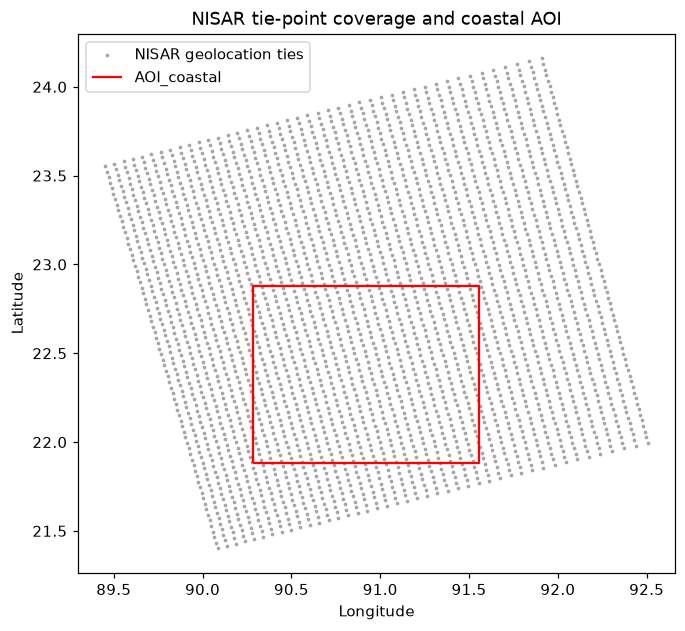

In [3]:
# Load the AOI, then use the sparse NISAR geolocation grid to find the radar-coordinate
# (line/sample) window of the full-resolution image that covers the AOI.

# 1. Load the AOI polygon and make sure it is in geographic coordinates (EPSG:4326) to
#    match the lon/lat tie points stored in the geolocation grid.
aoi = gpd.read_file(AOI_PATH)
if aoi.crs is None:  # assume WGS 84 when the file has no CRS
    aoi = aoi.set_crs("EPSG:4326")  # set it
aoi_ll = aoi.to_crs("EPSG:4326")  # the AOI in longitude/latitude
min_lon, min_lat, max_lon, max_lat = aoi_ll.total_bounds  # its bounding box

GEO = "/science/LSAR/RSLC/metadata/geolocationGrid"  # HDF5 path of the geolocation grid
SWATH = "/science/LSAR/RSLC/swaths/frequencyA"  # HDF5 path of the frequency-A swath
with h5py.File(SCENE, "r") as f:  # open the RSLC file
    swath = f[SWATH]  # the swath group
    geo = f[GEO]  # the geolocation group
    n_lines, n_samples = swath["HH"].shape  # image size
    # 2. The geolocation grid stores tie points at several terrain heights above the
    #    ellipsoid; pick the slice closest to zero metres for this quick-look workflow.
    heights = geo["heightAboveEllipsoid"][:]
    height_index = int(np.argmin(np.abs(heights)))  # the grid layer closest to zero height
    tie_lon = geo["coordinateX"][height_index, :, :]  # longitude of every tie point
    tie_lat = geo["coordinateY"][height_index, :, :]  # latitude of every tie point
    tie_range = geo["slantRange"][:]  # slant range of the tie-point columns
    scene_range = swath["slantRange"][:]  # slant range of the image columns
    valid_ranges = swath["validSamplesSubSwath1"]  # valid range samples of each line

    # 3. Find which tie points fall inside the AOI's lon/lat bounding box. These are
    #    coarse, sparse grid points, so this only approximately brackets the AOI.
    intersects = (
        np.isfinite(tie_lon) & np.isfinite(tie_lat)
        & (tie_lon >= min_lon) & (tie_lon <= max_lon)
        & (tie_lat >= min_lat) & (tie_lat <= max_lat)
    )
    tie_rows, tie_cols = np.where(intersects)  # tie points that fall inside the AOI
    if tie_rows.size == 0:  # none: the AOI is outside the scene
        raise ValueError("The AOI does not intersect the RSLC geolocation grid")  # stop with a clear message

    # 4. Convert the matching tie-point row/column indices into full-resolution
    #    line/sample pixel indices, padding by two tie-point intervals on each side so
    #    later interpolation near the AOI edge has neighboring samples to draw on.
    tie_line_to_pixel = np.linspace(0, n_lines - 1, tie_lon.shape[0])
    # first image line of the AOI window (with a margin)
    row_low = max(0, int(np.floor(tie_line_to_pixel[max(0, tie_rows.min() - 2)])))
    # last image line
    row_high = min(n_lines, int(np.ceil(tie_line_to_pixel[min(tie_lon.shape[0] - 1, tie_rows.max() + 2)])) + 1)
    # tie-point column -> image sample
    tie_sample_to_pixel = np.interp(tie_range, scene_range, np.arange(n_samples))
    col_low = max(0, int(np.floor(tie_sample_to_pixel[max(0, tie_cols.min() - 2)])))  # first image sample
    # last image sample
    col_high = min(n_samples, int(np.ceil(tie_sample_to_pixel[min(tie_lon.shape[1] - 1, tie_cols.max() + 2)])) + 1)

# 5. Report the AOI bounds, the chosen height slice, and the resulting radar window so
#    we know up front how much of the ~2.9 billion-sample scene will actually be read.
print(f"AOI bounds (longitude, latitude): {min_lon:.5f}, {min_lat:.5f}, {max_lon:.5f}, {max_lat:.5f}")
print(f"Zero-height geolocation slice: {heights[height_index]:.0f} m")  # height of the grid layer used
print(f"Radar window: lines {row_low:,}:{row_high:,}, samples {col_low:,}:{col_high:,}")  # the radar window
print(f"Window size: {row_high-row_low:,} x {col_high-col_low:,} single-look samples")  # its size

# 6. Plot the (subsampled) tie-point coverage against the AOI boundary as a sanity
#    check that the AOI truly falls within the scene footprint before reading pixels.
fig, ax = plt.subplots(figsize=(7, 7))
# tie points (every eighth)
ax.scatter(tie_lon[::8, ::8], tie_lat[::8, ::8], s=2, color="0.65", label="NISAR geolocation ties")
aoi_ll.boundary.plot(ax=ax, color="red", linewidth=1.5, label="AOI_coastal")  # the AOI outline
# labels and title
ax.set(xlabel="Longitude", ylabel="Latitude", title="NISAR tie-point coverage and coastal AOI")
ax.legend()  # legend
ax.set_aspect("equal", adjustable="box")  # equal scale
plt.show()  # draw

## Stream and multilook the complex RSLC

The code below calculates `mean(|S|²)` over 64 × 64 blocks. It limits working memory by reading a few multilooked output rows at a time. NISAR's `validSamplesSubSwath1` start/end indices are used to ignore samples outside the valid range swath. This is a block-averaged intensity product; it does not average complex phase and should not be used as an SLC interferogram input.


In [4]:
# Stream the AOI window of the complex HH/HV arrays in bounded chunks and compute
# multilooked linear beta0 power (mean of |S|^2), honoring the valid-sample range mask.

LOOKS = (64, 64)  # (azimuth lines, range samples)
OUTPUT_ROWS_PER_CHUNK = 4  # multilooked rows computed per read

# multilooked power of a radar window, read chunk by chunk from the HDF5 file
def read_multilooked_power(dataset, valid_sample_dataset, window, looks=LOOKS,
                           output_rows_per_chunk=OUTPUT_ROWS_PER_CHUNK):
    """Stream a radar-window block average of complex SLC power."""
    # 1. Unpack the window and derive how many complete multilook blocks fit in it,
    #    trimming the window so every output pixel is backed by a full look x look block.
    line0, line1, sample0, sample1 = window
    look_az, look_rg = looks  # azimuth and range looks
    out_lines = (line1 - line0) // look_az  # output lines
    out_samples = (sample1 - sample0) // look_rg  # output samples
    line1 = line0 + out_lines * look_az  # trim the window to whole looks
    sample1 = sample0 + out_samples * look_rg  # trim the window to whole looks
    output = np.full((out_lines, out_samples), np.nan, dtype="float32")  # output array
    sample_indices = np.arange(sample0, sample1)  # image sample numbers of the window

    # 2. Process a few multilooked output rows at a time (output_rows_per_chunk) so only
    #    a small slab of the multi-gigabyte complex HDF5 dataset is held in memory at once.
    for out0 in range(0, out_lines, output_rows_per_chunk):
        count = min(output_rows_per_chunk, out_lines - out0)  # output rows in this chunk
        raw0 = line0 + out0 * look_az  # first input line of the chunk
        raw1 = raw0 + count * look_az  # last input line of the chunk
        # 3. Read this chunk's raw complex samples and convert to linear power |S|^2
        #    (real^2 + imag^2); this is the single-look beta0-proportional power.
        block = dataset[raw0:raw1, sample0:sample1]
        # power = real² + imaginary²
        power = block.real.astype("float32") ** 2 + block.imag.astype("float32") ** 2
        # 4. Mask out samples outside the valid range swath for each line, using NISAR's
        #    per-line validSamplesSubSwath1 start/end indices, so invalid fill data does
        #    not get averaged into the multilooked power.
        valid = valid_sample_dataset[raw0:raw1]
        valid_pixels = (  # mask of samples inside each line's valid range
            (sample_indices[None, :] >= valid[:, 0, None])
            & (sample_indices[None, :] <= valid[:, 1, None])
        )
        power[~valid_pixels] = np.nan  # invalid samples -> NaN
        # 5. Reshape into (output_rows, look_az, output_cols, look_rg) blocks and average
        #    only the finite (valid) samples in each look x look block, leaving a block
        #    NaN only if it contains no valid samples at all.
        blocks = power.reshape(count, look_az, out_samples, look_rg)
        finite = np.isfinite(blocks)  # finite values in each look block
        totals = np.where(finite, blocks, 0).sum(axis=(1, 3))  # sum of the finite values per block
        counts = finite.sum(axis=(1, 3))  # number of finite values per block
        output[out0:out0 + count] = np.divide(  # mean power per block
            totals, counts, out=np.full_like(totals, np.nan), where=counts > 0
        )
    return output  # the multilooked power

# 6. Snap the AOI window from Step 2 down to a whole number of 64x64 look blocks so the
#    multilooked output arrays below have well-defined, consistent dimensions.
window = (row_low, row_high, col_low, col_high)
n_lines_ml = (row_high - row_low) // LOOKS[0]  # multilooked lines
n_samples_ml = (col_high - col_low) // LOOKS[1]  # multilooked samples
row_high = row_low + n_lines_ml * LOOKS[0]  # trim the window to whole looks
col_high = col_low + n_samples_ml * LOOKS[1]  # trim the window to whole looks
window = (row_low, row_high, col_low, col_high)  # the final window

# 7. Stream and multilook the HH and HV complex arrays over the trimmed window. Each
#    call only ever touches the AOI window, never the full ~2.9 billion-sample scene.
with h5py.File(SCENE, "r") as f:
    swath = f[SWATH]  # the swath group
    valid_samples = swath["validSamplesSubSwath1"]  # valid range samples of each line
    # HH beta0 (uncalibrated power), multilooked
    beta0_hh_values = read_multilooked_power(swath["HH"], valid_samples, window)
    beta0_hv_values = read_multilooked_power(swath["HV"], valid_samples, window)  # HV beta0, multilooked

# size of the multilooked arrays
print(f"Multilooked arrays: {beta0_hh_values.shape[0]:,} x {beta0_hh_values.shape[1]:,}")
print(f"HH beta0 valid fraction: {np.isfinite(beta0_hh_values).mean():.1%}")  # valid share of HH
print(f"HV beta0 valid fraction: {np.isfinite(beta0_hv_values).mean():.1%}")  # valid share of HV

Multilooked arrays: 486 x 521
HH beta0 valid fraction: 100.0%
HV beta0 valid fraction: 100.0%


## Incidence-angle correction, filtering, and dB display

NISAR RSLC samples are calibrated to beta-nought. The approximate ellipsoid sigma-nought is `beta0 × sin(incidence angle)`. Both beta0 and sigma0 are kept in linear power for filtering; dB conversion is only for visualization. Terrain-flattened gamma0 is not computed here.


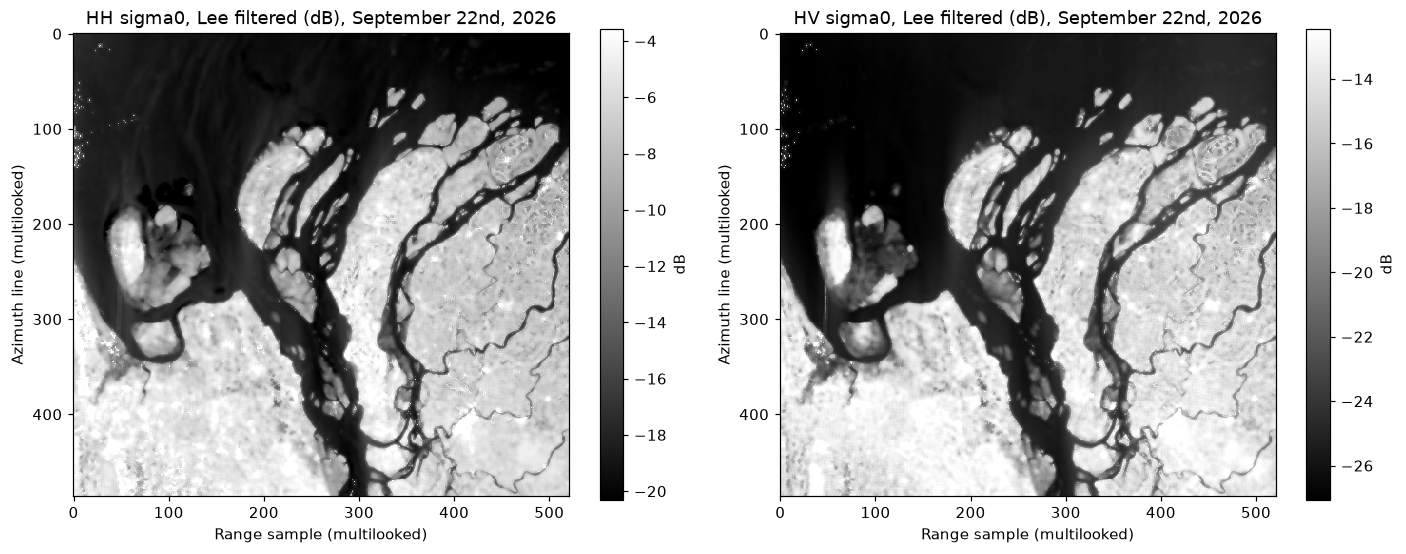

In [5]:
# Interpolate the incidence-angle grid onto the multilooked pixel locations, convert
# beta0 to an ellipsoid sigma0 approximation, Lee-filter the linear power, and display in dB.

# 1. Build coordinate-mapping arrays that translate multilooked (azimuth, range) pixel
#    centers into fractional tie-point grid indices, so the sparse incidence-angle grid
#    can be interpolated onto the exact multilooked sample locations.
geo_line_positions = np.linspace(0, image_shape[0] - 1, tie_lon.shape[0])
geo_sample_positions = tie_sample_to_pixel  # tie-point column positions in image samples
# image line at the centre of each multilooked row
ml_lines = row_low + (np.arange(n_lines_ml) + 0.5) * LOOKS[0]
# image sample at the centre of each multilooked column
ml_samples = col_low + (np.arange(n_samples_ml) + 0.5) * LOOKS[1]
# multilooked rows -> fractional tie-point rows
tie_line_coords = np.interp(ml_lines, geo_line_positions, np.arange(tie_lon.shape[0]))
# multilooked columns -> fractional tie-point columns
tie_sample_coords = np.interp(ml_samples, geo_sample_positions, np.arange(tie_lon.shape[1]))
# fractional tie-point coordinates of every multilooked pixel
sample_grid = np.meshgrid(tie_line_coords, tie_sample_coords, indexing="ij")

# 2. Read the incidence-angle tie points at the same zero-height slice used for the AOI
#    window, then bilinearly interpolate them onto the multilooked grid built above.
with h5py.File(SCENE, "r") as f:
    geo = f[GEO]  # the geolocation group
    incidence_ties = geo["incidenceAngle"][height_index, :, :]  # incidence angle at the tie points

# incidence angle of every multilooked pixel (bilinear)
incidence_deg = map_coordinates(incidence_ties, sample_grid, order=1, mode="nearest")
# 3. Wrap the multilooked HH/HV beta0 power arrays as labeled xarray DataArrays so
#    azimuth/range coordinates and units/polarization metadata travel with the data.
coords = {"azimuth": ml_lines, "range": ml_samples}
beta0_hh = xr.DataArray(beta0_hh_values, dims=("azimuth", "range"), coords=coords,  # HH beta0 as a DataArray
                        name="beta0_hh", attrs={"units": "linear beta0", "polarization": "HH"})
beta0_hv = xr.DataArray(beta0_hv_values, dims=("azimuth", "range"), coords=coords,  # HV beta0 as a DataArray
                        name="beta0_hv", attrs={"units": "linear beta0", "polarization": "HV"})
# 4. Approximate ellipsoid sigma0 as beta0 * sin(incidence angle); this is a geometric
#    approximation, not a terrain-flattened radiometric correction.
sigma0_hh = beta0_hh * np.sin(np.deg2rad(incidence_deg))
sigma0_hv = beta0_hv * np.sin(np.deg2rad(incidence_deg))  # sigma0 = beta0 x sin(incidence)
sigma0_hh.name, sigma0_hv.name = "sigma0_hh", "sigma0_hv"  # names
sigma0_hh.attrs["units"] = sigma0_hv.attrs["units"] = "linear sigma0"  # units

# 5. Apply GeoLattice Lee speckle filtering to the linear sigma0 power (never to dB values),
# which preserves the physical units while suppressing multiplicative speckle noise.
sigma0_hh_lee = xr.DataArray(rs.sar.lee(sigma0_hh.values, size=5), dims=sigma0_hh.dims,
                            coords=sigma0_hh.coords, name="sigma0_hh_lee")
# Lee speckle filter (5 x 5)
sigma0_hv_lee = xr.DataArray(rs.sar.lee(sigma0_hv.values, size=5), dims=sigma0_hv.dims,
                            coords=sigma0_hv.coords, name="sigma0_hv_lee")
# 6. Convert the filtered linear sigma0 to dB only for visualization; downstream
#    quantities (Step 5 geocoding) continue to use the linear arrays, not these dB ones.
hh_db = rs.sar.to_db(sigma0_hh_lee)
hv_db = rs.sar.to_db(sigma0_hv_lee)  # filtered HV in dB

# 7. Display HH and HV side by side, stretching each image independently between its
#    2nd and 98th percentile dB values so both channels show useful contrast.
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, image, title in (  # the three images with their titles
    (axes[0], hh_db, "HH sigma0, Lee filtered (dB), September 22nd, 2026"),
    (axes[1], hv_db, "HV sigma0, Lee filtered (dB), September 22nd, 2026"),
):
    low, high = np.nanpercentile(image.values, [2, 98])  # 2-98 % stretch limits
    shown = ax.imshow(image, cmap="gray", vmin=low, vmax=high, interpolation="nearest")  # show the image
    # title and axis labels
    ax.set(title=title, xlabel="Range sample (multilooked)", ylabel="Azimuth line (multilooked)")
    fig.colorbar(shown, ax=ax, shrink=0.75, label="dB")  # colour bar
plt.tight_layout()  # arrange
plt.show()  # draw

The contrast stretch above uses the valid-pixel 2nd and 98th percentiles for display only. It does not alter the underlying linear beta0 or sigma0 arrays.


## Interpolate the quick look to a map grid

The sparse NISAR geolocation tie points are linearly interpolated to the multilooked sample locations at zero metres ellipsoidal height. GeoLattice `nisar.geocode_l1` then interpolates the quick-look sigma0 layers to a 200 m UTM grid. Finally, the exact GeoJSON polygon is used to clip the result to the study area.


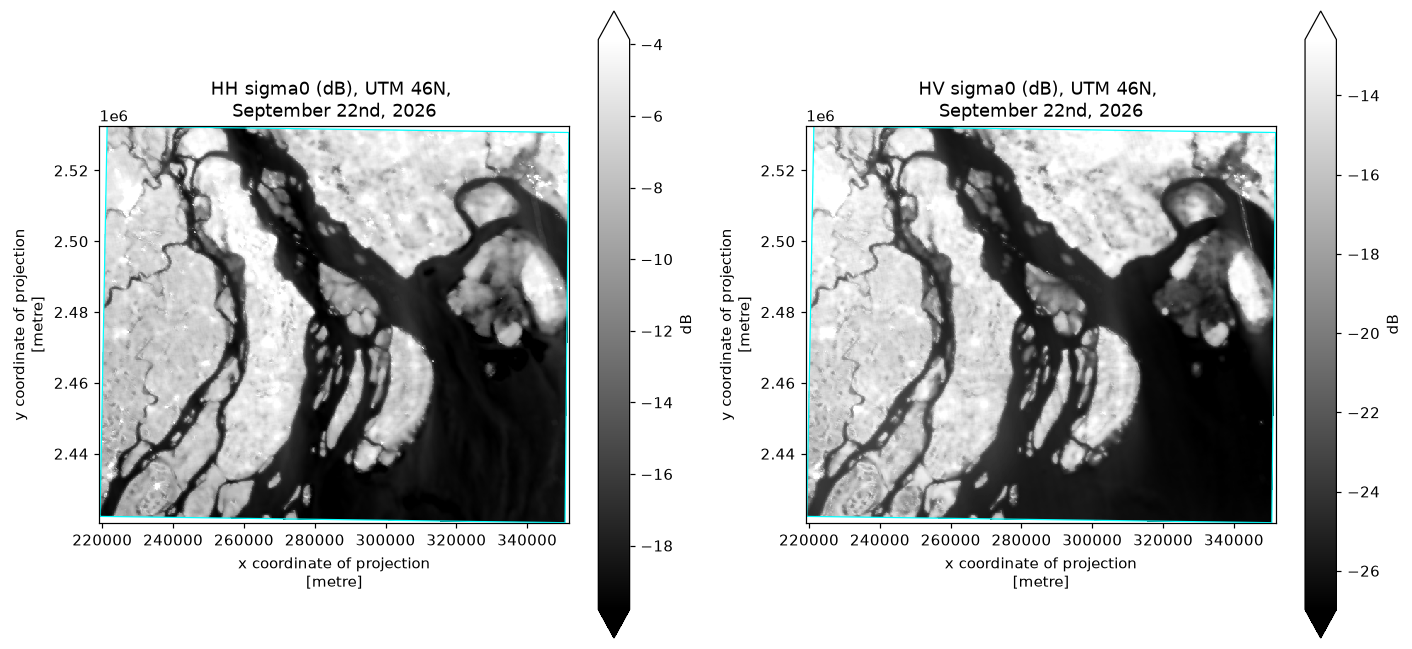

Clipped quick-look grid: 561 rows x 663 columns
Map CRS: EPSG:32646; pixel size: 200 m


In [6]:
# Interpolate tie-point lon/lat onto the multilooked grid, project to UTM, geocode the
# filtered sigma0 quick looks to a 200 m grid, and clip to the exact AOI polygon.

# 1. Interpolate the sparse lon/lat tie points onto the multilooked sample locations
#    (same index grid used for the incidence angle in Step 4) to get a map coordinate
#    for every multilooked pixel.
tie_x = map_coordinates(tie_lon, sample_grid, order=1, mode="nearest")
tie_y = map_coordinates(tie_lat, sample_grid, order=1, mode="nearest")  # latitude of every multilooked pixel
# 2. Project those geographic coordinates into the local UTM zone (46N covers coastal
#    Bangladesh) so the geocoded quick look has a metric, map-projected grid.
to_utm = Transformer.from_crs("EPSG:4326", "EPSG:32646", always_xy=True)
map_x, map_y = to_utm.transform(tie_x, tie_y)  # longitude/latitude -> UTM

# 3. Use GeoLattice's nisar.geocode_l1 to resample the irregularly-spaced radar-coordinate
#    sigma0 quick looks onto a regular 200 m UTM grid, using the per-pixel map_x/map_y
#    coordinates computed above.
MAP_RESOLUTION_M = 200
geo_hh = nisar.geocode_l1(  # geocode HH onto a UTM grid
    sigma0_hh_lee, map_x, map_y, epsg=32646, resolution=MAP_RESOLUTION_M
)
geo_hv = nisar.geocode_l1(  # geocode HV onto a UTM grid
    sigma0_hv_lee, map_x, map_y, epsg=32646, resolution=MAP_RESOLUTION_M
)
# 4. Clip the geocoded grids to the exact AOI polygon (reprojected to UTM), rather than
#    the coarser radar-window bounding box used earlier, to remove the extra padding.
aoi_utm = aoi.to_crs("EPSG:32646")
geo_hh = geo_hh.rio.clip(aoi_utm.geometry, aoi_utm.crs, drop=True, all_touched=True)  # clip HH to the AOI
geo_hv = geo_hv.rio.clip(aoi_utm.geometry, aoi_utm.crs, drop=True, all_touched=True)  # clip HV to the AOI
# 5. Convert the clipped linear sigma0 grids to dB for the final map display.
geo_hh_db = rs.sar.to_db(geo_hh).rename("sigma0_hh_db")
geo_hv_db = rs.sar.to_db(geo_hv).rename("sigma0_hv_db")  # HV in dB

# 6. Plot the geocoded, clipped HH/HV dB quick looks with the AOI boundary overlaid for
#    visual confirmation that the map-projected result matches the requested study area.
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, image, title in (  # the two images with their titles
    (axes[0], geo_hh_db, "HH sigma0 (dB), UTM 46N, \nSeptember 22nd, 2026"),
    (axes[1], geo_hv_db, "HV sigma0 (dB), UTM 46N, \nSeptember 22nd, 2026"),
):
    # show with a robust stretch
    image.plot.imshow(ax=ax, cmap="gray", robust=True, cbar_kwargs={"label": "dB"})
    aoi_utm.boundary.plot(ax=ax, color="cyan", linewidth=0.8)  # AOI outline
    ax.set_title(title)  # title
    ax.set_aspect("equal")  # equal scale
plt.tight_layout()  # arrange
plt.show()  # draw

print(f"Clipped quick-look grid: {geo_hh.sizes['y']:,} rows x {geo_hh.sizes['x']:,} columns")  # grid size
print(f"Map CRS: {geo_hh.rio.crs}; pixel size: {MAP_RESOLUTION_M} m")  # CRS and pixel size

## HH/HV dual-polarization RGB composite

Create a false-color composite from the clipped, geocoded dB quick looks: red = HH sigma0 (dB), green = HV sigma0 (dB), and blue = HH−HV (dB), equivalent to the HH/HV power ratio expressed in decibels. Each channel is contrast-stretched independently between its 2nd and 98th percentiles for display; this RGB is for visual interpretation, not quantitative color measurement.


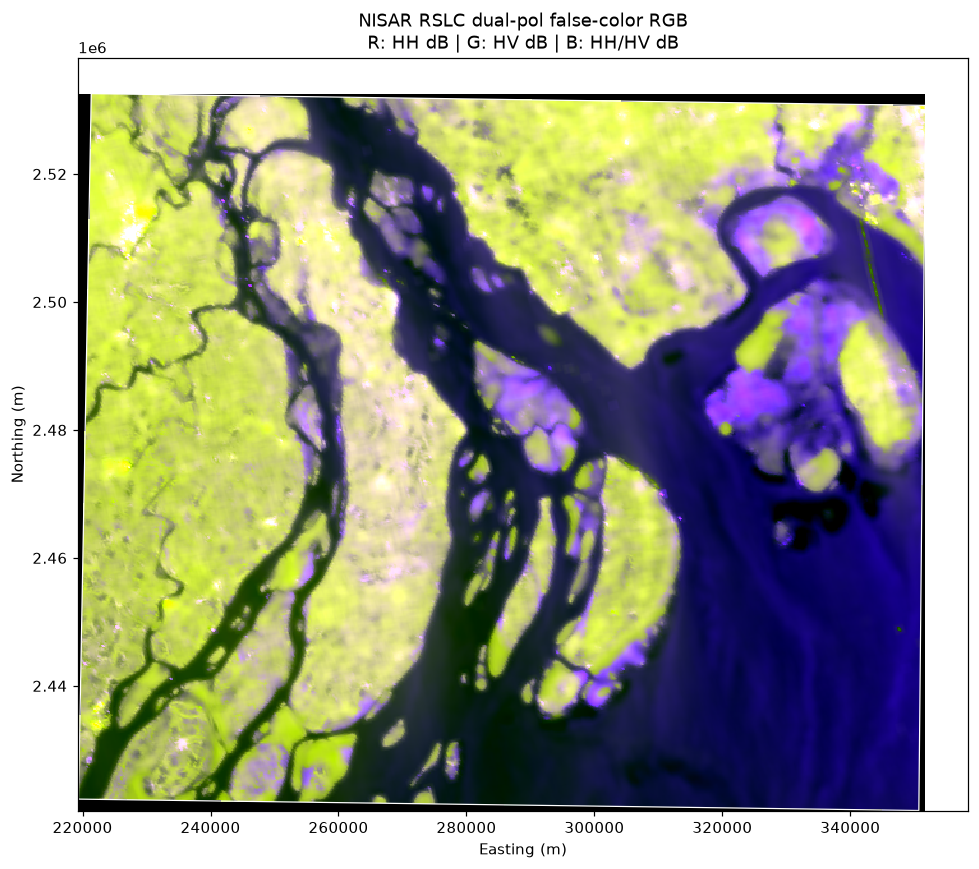

In [7]:
# Build a false-color RGB composite (R=HH dB, G=HV dB, B=HH-HV dB ratio) from the
# clipped geocoded quick looks, with each channel independently percentile-stretched.

# 1. Pull the dB arrays as plain float32 numpy arrays and derive the third ('blue')
#    channel as the HH-HV difference in dB, equivalent to the HH/HV power ratio.
hh_rgb = geo_hh_db.values.astype("float32")
hv_rgb = geo_hv_db.values.astype("float32")  # HV in dB as an array
ratio_rgb = hh_rgb - hv_rgb  # HH minus HV (dB): the cross-polarisation ratio
valid_rgb = np.isfinite(hh_rgb) & np.isfinite(hv_rgb)  # pixels valid in both

# 2. Helper that linearly stretches one channel's finite pixels between given
#    percentiles into the [0, 1] range expected by matplotlib's imshow for RGB images.
def stretch_rgb_channel(channel, valid_mask, percentiles=(2, 98)):
    values = channel[valid_mask]  # the valid values of the channel
    if values.size == 0:  # no valid values
        raise ValueError("RGB channel has no finite pixels in the clipped AOI")  # stop with a clear message
    low, high = np.percentile(values, percentiles)  # percentile limits
    if high <= low:  # constant channel
        return np.zeros(channel.shape, dtype="float32")  # return zeros
    return np.clip((channel - low) / (high - low), 0, 1).astype("float32")  # stretch to [0, 1]

# 3. Stretch each of the three channels independently (each has its own dB range) and
#    stack them into an (rows, cols, 3) RGB array; zero out any pixel invalid in HH or HV.
rgb = np.stack([
    stretch_rgb_channel(hh_rgb, valid_rgb),
    stretch_rgb_channel(hv_rgb, valid_rgb),
    stretch_rgb_channel(ratio_rgb, valid_rgb),
], axis=-1)
rgb[~valid_rgb] = 0  # no-data pixels in black

# 4. Plot the RGB composite on its UTM map extent, with the AOI boundary overlaid in
#    white for visual reference against the coastline and surface features.
x = geo_hh_db.x.values
y = geo_hh_db.y.values  # northing values
extent = (x.min(), x.max(), y.min(), y.max())  # map extent
fig, ax = plt.subplots(figsize=(9, 8))  # one panel
ax.imshow(rgb, extent=extent, origin="upper", interpolation="nearest")  # the RGB composite
aoi_utm.boundary.plot(ax=ax, color="white", linewidth=0.8)  # AOI outline
ax.set(xlabel="Easting (m)", ylabel="Northing (m)",  # axis labels and title
       title="NISAR RSLC dual-pol false-color RGB\nR: HH dB | G: HV dB | B: HH/HV dB")
ax.set_aspect("equal")  # equal scale
plt.tight_layout()  # arrange
plt.show()  # draw

## Optionally export the clipped quick looks

Exports are disabled by default. When enabled, the files are small, georeferenced dB quick looks; they are not source-resolution NISAR products and should not be labeled as terrain-corrected RTC.


In [8]:
# Optionally write the clipped, geocoded dB quick looks to GeoTIFFs; disabled by default
# so running the notebook does not silently create output files on disk.

# 1. Flip this flag to True to export; when False (the default) the block below is
#    skipped entirely and no files are written.
WRITE_OUTPUTS = False
if WRITE_OUTPUTS:  # only when output writing is switched on
    # 2. Create the output directory (if needed) and write each polarization's dB
    #    quick look as an LZW-compressed GeoTIFF carrying its UTM georeferencing.
    output_dir = DATA_DIR / "quicklooks"
    output_dir.mkdir(parents=True, exist_ok=True)  # create the output folder
    # save HH in dB
    geo_hh_db.rio.to_raster(output_dir / "NISAR_RSLC_HH_sigma0_db_quicklook.tif", compress="LZW")
    # save HV in dB
    geo_hv_db.rio.to_raster(output_dir / "NISAR_RSLC_HV_sigma0_db_quicklook.tif", compress="LZW")
    print(f"Wrote quick looks to {output_dir.resolve()}")  # where the files were written

## Interpretation and next steps

- Bright HH returns indicate stronger co-polarized backscatter; HV highlights depolarizing vegetation and rough surfaces. Water is typically dark in both channels, subject to wind, incidence geometry, and local conditions.
- The beta0-to-sigma0 conversion here is an ellipsoid-incidence approximation. For radiometric terrain correction and map-projected analysis, use the matching NISAR GCOV product or an ISCE3 workflow with a DEM.
- The sparse geolocation grid and `geocode_l1` interpolation provide an exploratory map only. They do not model terrain-dependent radar visibility, layover, or shadow.
- For multi-date deformation, use matched RSLCs and a full InSAR workflow: precise orbit/DEM-assisted co-registration, complex interferogram formation, coherence, phase filtering, unwrapping, referencing, displacement conversion, and terrain-aware geocoding. The outputs in this notebook are intensity quick looks, not phase-preserving SLC data.
